# Residual load: dynamics

Residual-load persistence and daily and weekly cycles are examined over 2023–2024. Decomposition separates slower changes in level, repeating seasonal patterns, and remaining variation. Lag relationships describe how closely current residual load resembles earlier observations.

Values represent MWh per 15-minute interval. Daily and weekly cycles correspond to 96 and 672 intervals. With two years of observations, annual patterns have limited replication.


## 1. Setup

In [1]:
from pathlib import Path
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/experiments/chronos2.yaml').exists())
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT / 'notebooks' / 'eda' / '02_target_dynamics')
CONFIG_PATH = PROJECT_ROOT / 'configs/experiments/chronos2.yaml'
config = yaml.safe_load(CONFIG_PATH.read_text(encoding='utf-8'))
data_cfg = config['data']
TARGET = 'Residual load [MWh]'
YEARS = [2023, 2024]
COLORS = ['#0072B2', '#D55E00']
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=COLORS)
plt.rcParams.update({'figure.figsize': (11, 4), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.options.display.float_format = '{:,.2f}'.format

from statsmodels.tsa.seasonal import MSTL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

## 2. Load development data

In [2]:
source = data_cfg['sources']['consumption']
raw = pd.read_csv(PROJECT_ROOT / source['development'])
dates = pd.to_datetime(raw[source['timestamp_column']], format='%b %d, %Y %I:%M %p', errors='raise')
utc = dates.dt.tz_localize(source['timezone'], ambiguous='infer').dt.tz_convert('UTC')
assert utc.notna().all() and utc.is_monotonic_increasing and not utc.duplicated().any()
values = pd.to_numeric(raw[TARGET], errors='coerce').replace([np.inf, -np.inf], np.nan)
df = pd.DataFrame({'target': values.to_numpy()}, index=pd.DatetimeIndex(utc, name='timestamp_utc'))
local = df.index.tz_convert('Europe/Berlin')
df = df.loc[local.year.isin(YEARS)].copy()
local = df.index.tz_convert('Europe/Berlin')
df['year'] = local.year
df['month'] = local.month
df['weekday'] = local.dayofweek
df['hour'] = local.hour
df['quarter_hour'] = local.hour + local.minute / 60
holidays = pd.read_csv(PROJECT_ROOT / data_cfg['sources']['holidays']['path'])
holiday_dates = pd.to_datetime(holidays['Datum']).dt.date
df['is_holiday'] = np.isin(local.date, holiday_dates).astype(int)
print(f'Source: {source["development"]}')
print(f'Target: {TARGET} | {len(df):,} intervals | Berlin years: {YEARS}')


Source: Dataset/raw/csv/Actual_consumption_2023_2024_Quarterhour.csv
Target: Residual load [MWh] | 70,176 intervals | Berlin years: [2023, 2024]


## 3. Temporal continuity

Regular 15-minute spacing preserves the meaning of daily and weekly lags. One missing target value is interpolated for these diagnostics. Fixed UTC cycles shift relative to Berlin clock time around daylight-saving transitions.

In [3]:
expected = pd.date_range(pd.Timestamp('2023-01-01', tz='Europe/Berlin').tz_convert('UTC'), pd.Timestamp('2025-01-01', tz='Europe/Berlin').tz_convert('UTC'), freq='15min', inclusive='left')
series = df['target'].reindex(expected)
missing_before = int(series.isna().sum())
series = series.interpolate(method='time', limit=4, limit_area='inside')
assert series.notna().all(), 'Unresolved gaps require inspection.'
print(f'{len(series):,} intervals, {missing_before} missing values filled for diagnostics only.')
print('Interpolation fills up to 4 intervals within a gap. Original observations remain unchanged in the overview. UTC supports fixed cycles, with local clock shifts around DST.')

70,176 intervals, 1 missing values filled for diagnostics only.
Interpolation fills up to 4 intervals within a gap. Original observations remain unchanged in the overview. UTC supports fixed cycles, with local clock shifts around DST.


### Observations

The complete timestamp grid means that a lag of 96 consistently spans 24 elapsed hours and a lag of 672 spans seven elapsed days. One interpolated target value affects a very small part of the two-year series. Around daylight-saving transitions, fixed elapsed-time lags can correspond to a different Berlin clock hour, which should be considered when interpreting local daily patterns.

## 4. Decomposition
### 4.1 Daily and weekly cycles

The daily cycle describes recurring variation within a day, while the weekly cycle captures differences across the week. Both components are estimated over the continuous development period.

In [4]:
decomposition = MSTL(series, periods=(96, 672), windows=(11, 15)).fit()
print('Continuous development fit: daily = 96 and weekly = 672 intervals.')
print('Annual variation is inspected through monthly profiles. Two years give limited evidence for a stable annual component.')

Continuous development fit: daily = 96 and weekly = 672 intervals.
Annual variation is inspected through monthly profiles. Two years give limited evidence for a stable annual component.


### 4.2 Trend

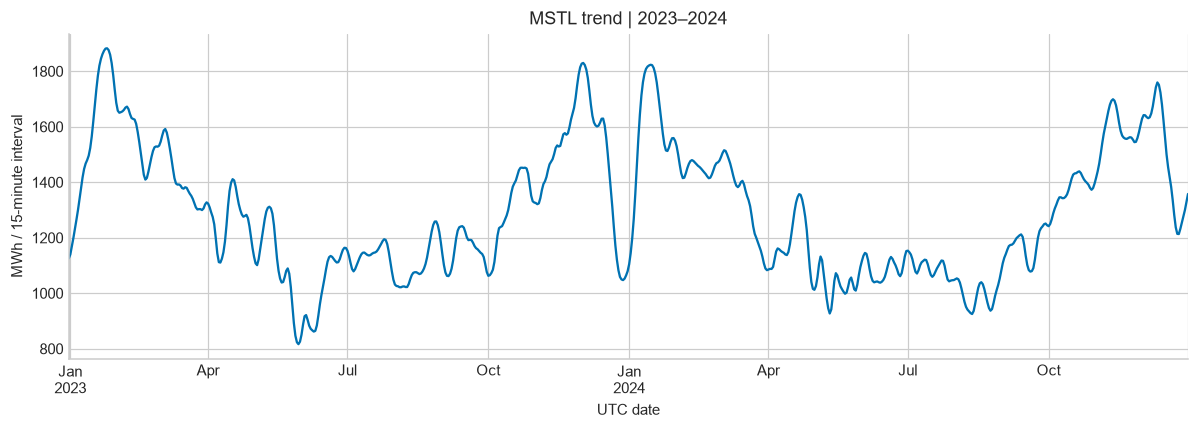

In [22]:
fig, ax = plt.subplots()
decomposition.trend.resample('D').mean().plot(ax=ax)
ax.set(title='MSTL trend | 2023–2024', xlabel='UTC date', ylabel='MWh / 15-minute interval')
fig.tight_layout()
fig.savefig('decomposition_trend.png', dpi=160, bbox_inches='tight')
plt.show()

### 4.3 Daily seasonal component

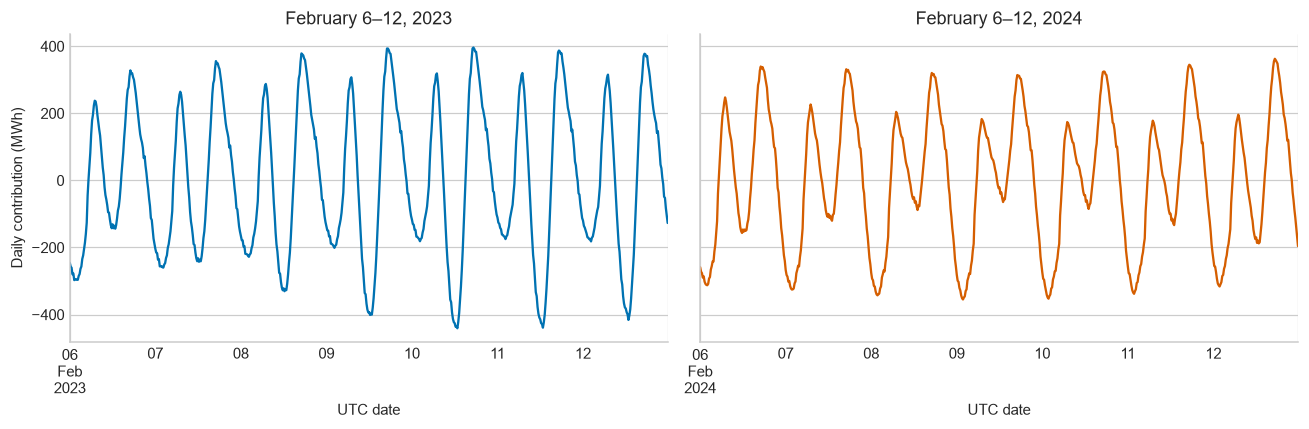

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
component = decomposition.seasonal['seasonal_96']
for ax, year in zip(axes, YEARS):
    component.loc[f'{year}-02-06':f'{year}-02-12'].plot(ax=ax, color=COLORS[YEARS.index(year)])
    ax.set(title=f'February 6–12, {year}', xlabel='UTC date', ylabel='Daily contribution (MWh)')
fig.tight_layout()
fig.savefig('decomposition_daily_seasonal_component.png', dpi=160, bbox_inches='tight')
plt.show()

### 4.4 Weekly seasonal component

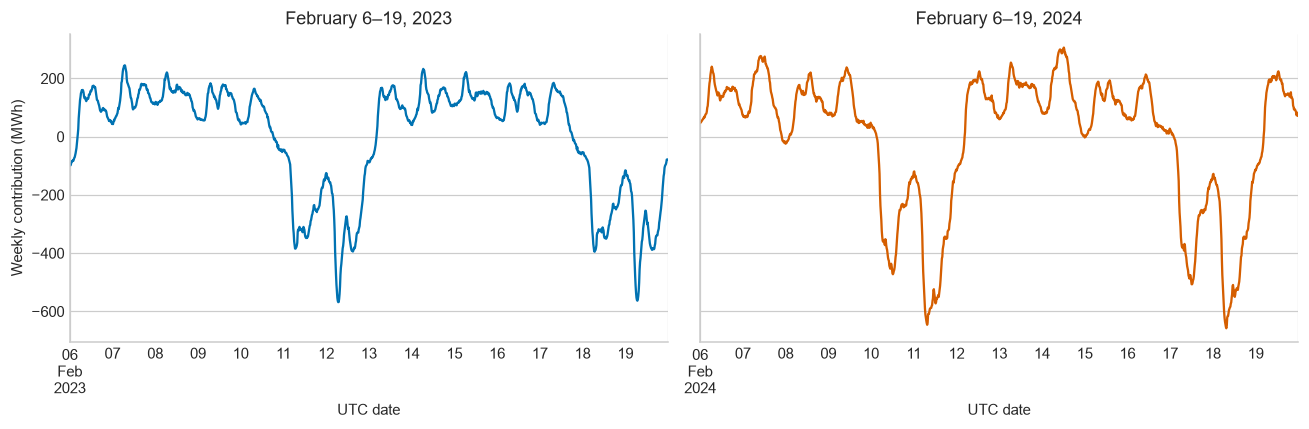

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
component = decomposition.seasonal['seasonal_672']
for ax, year in zip(axes, YEARS):
    component.loc[f'{year}-02-06':f'{year}-02-19'].plot(ax=ax, color=COLORS[YEARS.index(year)])
    ax.set(title=f'February 6–19, {year}', xlabel='UTC date', ylabel='Weekly contribution (MWh)')
fig.tight_layout()
fig.savefig('decomposition_weekly_seasonal_component.png', dpi=160, bbox_inches='tight')
plt.show()

### 4.5 Remainder

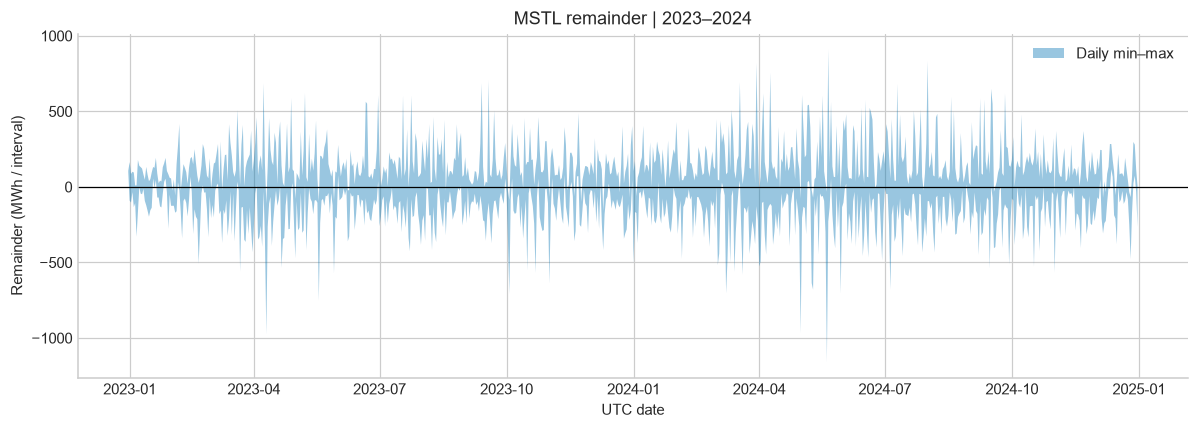

In [25]:
fig, ax = plt.subplots()
remainder_daily = decomposition.resid.resample('D').agg(['min', 'max'])
ax.fill_between(remainder_daily.index, remainder_daily['min'], remainder_daily['max'], alpha=.4, label='Daily min–max')
ax.axhline(0, color='black', linewidth=.8)
ax.set(title='MSTL remainder | 2023–2024', xlabel='UTC date', ylabel='Remainder (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('decomposition_remainder.png', dpi=160, bbox_inches='tight')
plt.show()

### 4.6 Reconstruction check

In [9]:
reconstructed = decomposition.trend + decomposition.seasonal.sum(axis=1) + decomposition.resid
assert np.allclose(series, reconstructed)
print(f'Maximum reconstruction error: {(series - reconstructed).abs().max():.3g} MWh per interval.')

Maximum reconstruction error: 9.09e-13 MWh per interval.


### Observations

The trend component preserves the broad winter-high and summer-low pattern, including the pronounced dip around the turn of 2024. Because the decomposition includes daily and weekly components, slower annual variation remains within this trend.

The February daily component has two positive peaks per day and negative contributions between them. The weekly component shows sustained positive contributions during working days and deep negative contributions at weekends, with Sunday troughs approaching −600 MWh per interval in the displayed windows.

The remainder contains substantial positive and negative excursions, especially during spring and summer 2024. Daily and weekly repetition therefore explains only part of the variation. Weather, changing renewable output, and special days are plausible contributors to the remaining deviations, whose causes require further evidence.

## 5. Lag plots

### 5.1 Lag 1 (0.25 hours)

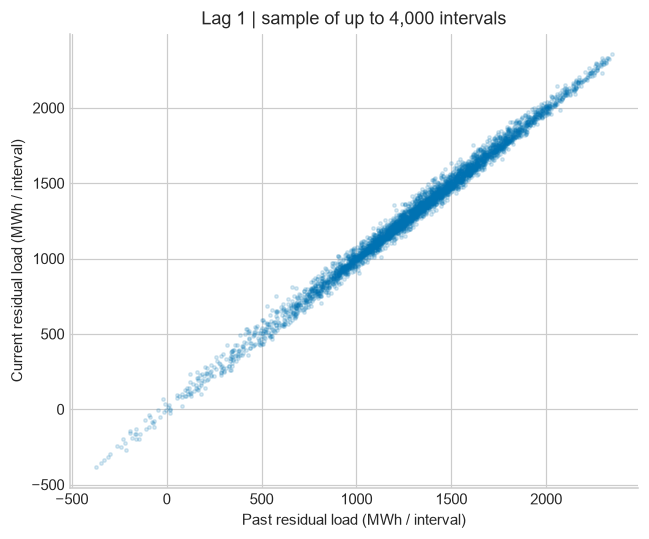

Full-data correlation: 0.997. Forecast improvement requires validation.


In [26]:
pairs = pd.DataFrame({'past': series.shift(1), 'current': series}).dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sample['past'], sample['current'], s=5, alpha=.15)
ax.set(title='Lag 1 | sample of up to 4,000 intervals', xlabel='Past residual load (MWh / interval)', ylabel='Current residual load (MWh / interval)')
fig.tight_layout()
fig.savefig('lag_plots_lag_1_0_25_hours.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Full-data correlation: {pairs.corr().iloc[0, 1]:.3f}. Forecast improvement requires validation.')

### 5.2 Lag 4 (1 hour)

Four quarter-hour intervals correspond to the one-hour spacing between forecast origins. This lag describes dependence across successive forecast origins within the 24-hour forecasting setup.

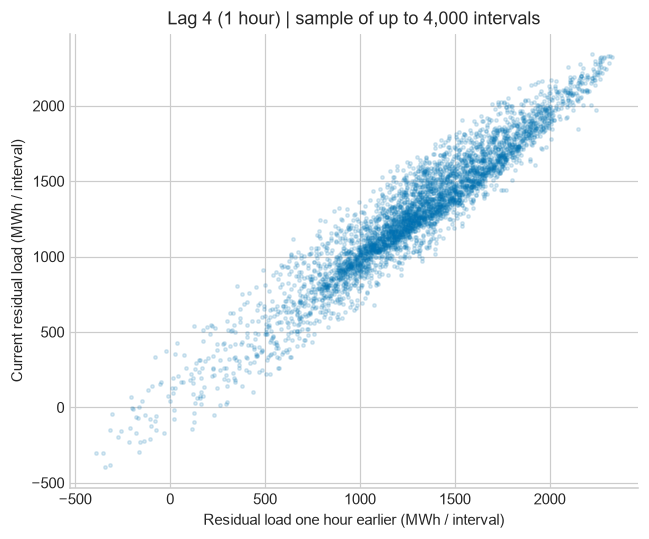

Full-data correlation: 0.957. The one-hour lag matches the forecast-origin step.


In [4]:
pairs = pd.DataFrame({'past': series.shift(4), 'current': series}).dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sample['past'], sample['current'], s=5, alpha=.15)
ax.set(title='Lag 4 (1 hour) | sample of up to 4,000 intervals', xlabel='Residual load one hour earlier (MWh / interval)', ylabel='Current residual load (MWh / interval)')
fig.tight_layout()
fig.savefig('lag_plots_lag_4_1_hour.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Full-data correlation: {pairs.corr().iloc[0, 1]:.3f}. The one-hour lag matches the forecast-origin step.')

### 5.3 Lag 96 (24 hours)

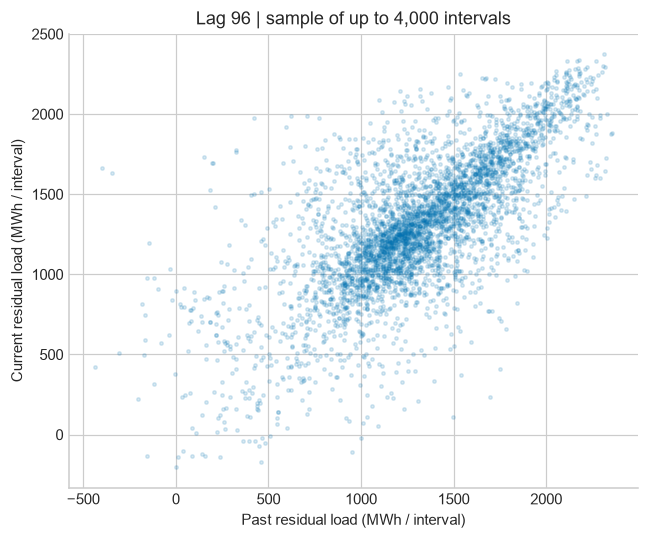

Full-data correlation: 0.714. Forecast improvement requires validation.


In [27]:
pairs = pd.DataFrame({'past': series.shift(96), 'current': series}).dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sample['past'], sample['current'], s=5, alpha=.15)
ax.set(title='Lag 96 | sample of up to 4,000 intervals', xlabel='Past residual load (MWh / interval)', ylabel='Current residual load (MWh / interval)')
fig.tight_layout()
fig.savefig('lag_plots_lag_96_24_hours.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Full-data correlation: {pairs.corr().iloc[0, 1]:.3f}. Forecast improvement requires validation.')

### 5.4 Lag 672 (168 hours)

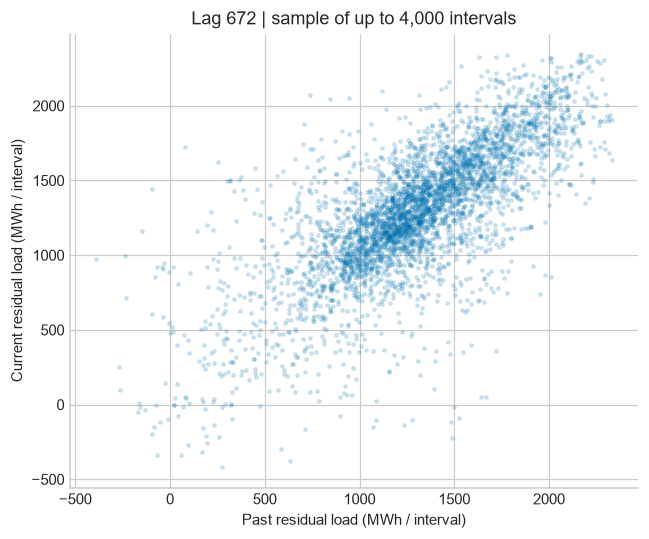

Full-data correlation: 0.747. Forecast improvement requires validation.


In [28]:
pairs = pd.DataFrame({'past': series.shift(672), 'current': series}).dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sample['past'], sample['current'], s=5, alpha=.15)
ax.set(title='Lag 672 | sample of up to 4,000 intervals', xlabel='Past residual load (MWh / interval)', ylabel='Current residual load (MWh / interval)')
fig.tight_layout()
fig.savefig('lag_plots_lag_672_168_hours.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Full-data correlation: {pairs.corr().iloc[0, 1]:.3f}. Forecast improvement requires validation.')

### Observations

The 15-minute lag forms a very narrow diagonal, with correlation 0.997. Adjacent residual-load observations usually change smoothly, which provides strong information for very short forecasts.

At one hour, the cloud remains close to the diagonal but widens, with correlation 0.957. This indicates strong persistence across successive hourly forecast origins, while the increased spread shows that meaningful ramps can occur within an hour. The one-hour interval is the spacing between forecast origins, and each forecast still spans the next 24 hours.

The one-day and one-week plots have much wider clouds. Their correlations are 0.714 and 0.747, respectively, consistent with a recurring weekday pattern alongside the daily cycle. Large deviations remain at both seasonal lags, particularly at low residual load. A recent observation can therefore be highly informative for the next interval while substantial uncertainty remains over a full day.

## 6. Autocorrelation

Autocorrelations describe the overall relationship between residual load and its earlier values. One observation lag represents 15 minutes, so lags 4, 96, and 672 correspond to one hour, one day, and one week.

### 6.1 Recent dependence: 15 minutes to six hours

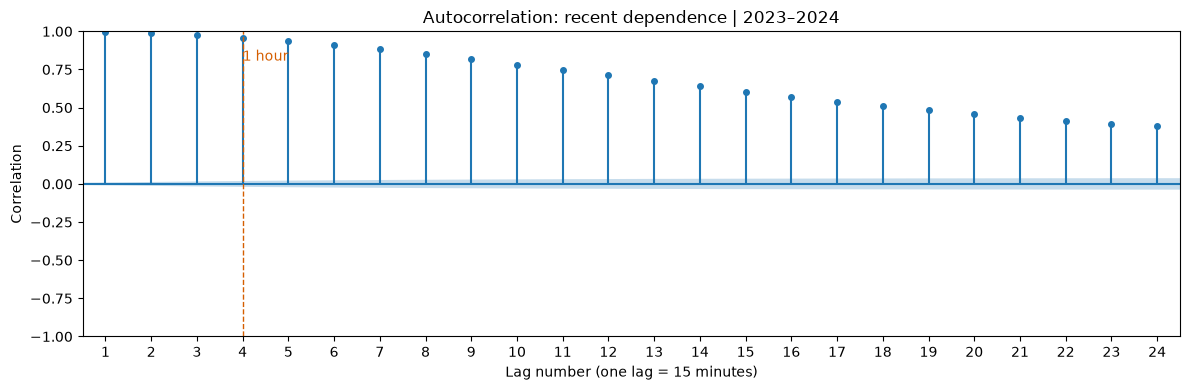

In [18]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(series, lags=24, fft=True, ax=ax, zero=False, markersize=4)
ax.axvline(4, color=COLORS[1], linestyle='--', linewidth=1)
ax.text(4, .94, '1 hour', transform=ax.get_xaxis_transform(), ha='left', va='top', color=COLORS[1])
ax.set(title='Autocorrelation: recent dependence | 2023–2024', xlabel='Lag number (one lag = 15 minutes)', ylabel='Correlation', xlim=(.5, 24.5))
ax.set_xticks(range(1, 25))
fig.tight_layout()
fig.savefig('autocorrelation_recent_lags.png', dpi=160, bbox_inches='tight')
plt.show()

### 6.2 Daily dependence: 24 hours

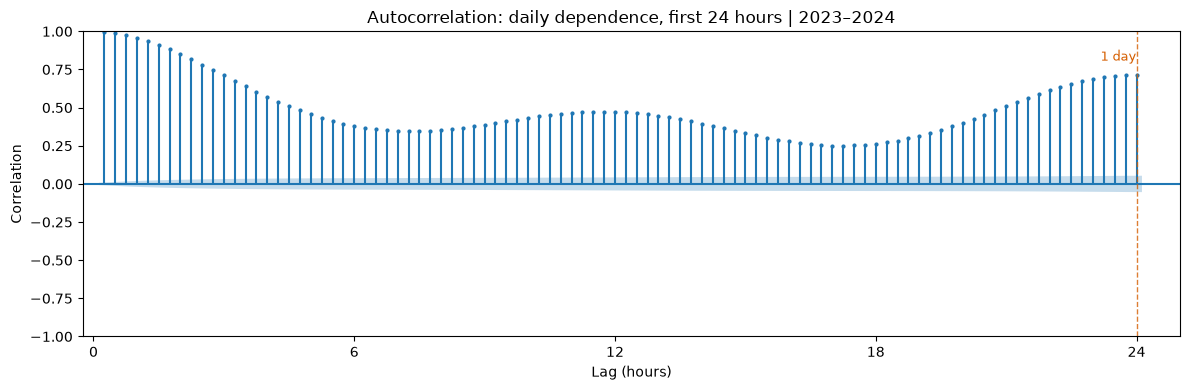

In [19]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(series, lags=96, fft=True, ax=ax, zero=False, markersize=2)
for lag, label, height in [(96, '1 day', .94)]:
    ax.axvline(lag, color=COLORS[1], linestyle='--', linewidth=1, alpha=.8)
    ax.text(lag, height, label, transform=ax.get_xaxis_transform(), ha='right' if lag == 96 else 'left', va='top', fontsize=9, color=COLORS[1])
ax.set(title='Autocorrelation: daily dependence, first 24 hours | 2023–2024', xlabel='Lag (hours)', ylabel='Correlation', xlim=(-1, 100))
ax.set_xticks([0, 24, 48, 72, 96], [0, 6, 12, 18, 24])
fig.tight_layout()
fig.savefig('autocorrelation_daily_lags.png', dpi=160, bbox_inches='tight')
plt.show()

### 6.3 Weekly dependence: seven days

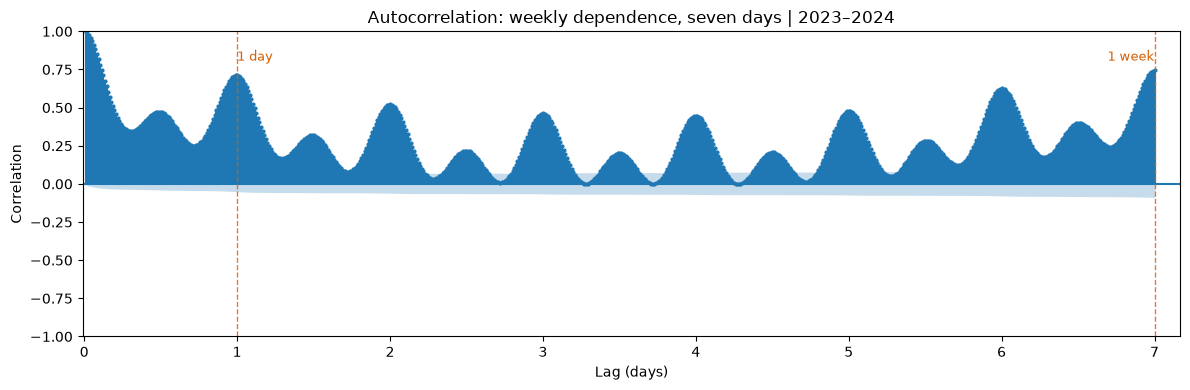

In [20]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(series, lags=672, fft=True, ax=ax, zero=False, markersize=2)
for lag, label, height in [(96, '1 day', .94), (672, '1 week', .94)]:
    ax.axvline(lag, color=COLORS[1], linestyle='--', linewidth=1, alpha=.8)
    ax.text(lag, height, label, transform=ax.get_xaxis_transform(), ha='right' if lag == 672 else 'left', va='top', fontsize=9, color=COLORS[1])
ax.set(title='Autocorrelation: weekly dependence, seven days | 2023–2024', xlabel='Lag (days)', ylabel='Correlation', xlim=(-1, 688))
ax.set_xticks([0, 96, 192, 288, 384, 480, 576, 672], [0, 1, 2, 3, 4, 5, 6, 7])
fig.tight_layout()
fig.savefig('autocorrelation_seasonal_lags.png', dpi=160, bbox_inches='tight')
plt.show()

### 6.4 Yearly comparison: recent hourly dependence

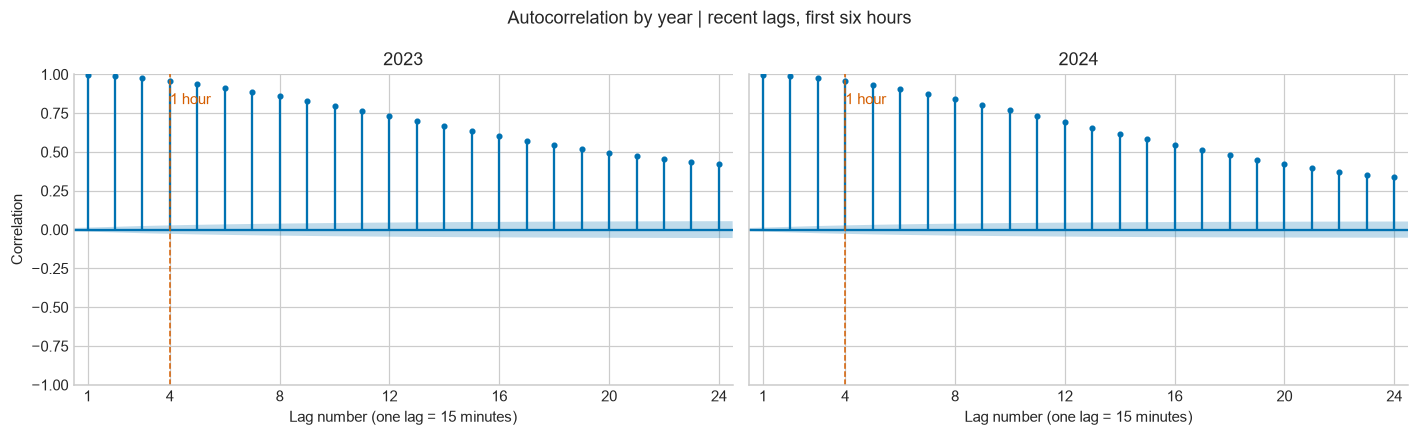

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, year in zip(axes, YEARS):
    subset = series.loc[series.index.tz_convert('Europe/Berlin').year == year]
    plot_acf(subset, lags=24, fft=True, ax=ax, zero=False, markersize=3)
    ax.axvline(4, color=COLORS[1], linestyle='--', linewidth=1)
    ax.text(4, .94, '1 hour', transform=ax.get_xaxis_transform(), ha='left', va='top', color=COLORS[1])
    ax.set(title=str(year), xlabel='Lag number (one lag = 15 minutes)', xlim=(.5, 24.5))
    ax.set_xticks([1, 4, 8, 12, 16, 20, 24])
axes[0].set_ylabel('Correlation')
fig.suptitle('Autocorrelation by year | recent lags, first six hours')
fig.tight_layout()
fig.savefig('autocorrelation_yearly_recent_lags.png', dpi=160, bbox_inches='tight')
plt.show()

### 6.5 Yearly comparison: 24 hours

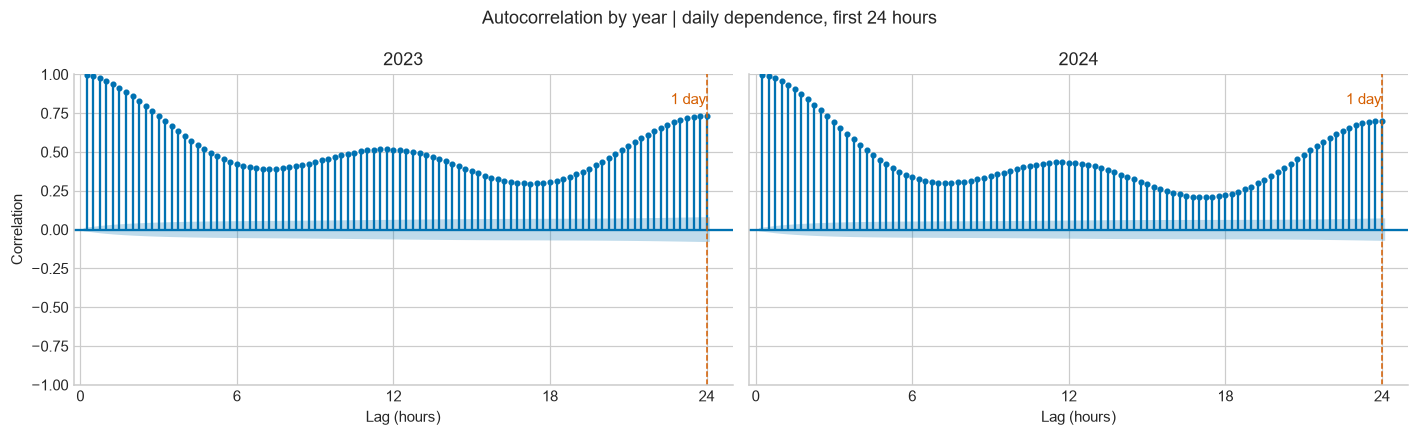

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, year in zip(axes, YEARS):
    subset = series.loc[series.index.tz_convert('Europe/Berlin').year == year]
    plot_acf(subset, lags=96, fft=True, ax=ax, zero=False, markersize=3)
    ax.axvline(96, color=COLORS[1], linestyle='--', linewidth=1)
    ax.text(96, .94, '1 day', transform=ax.get_xaxis_transform(), ha='right', va='top', color=COLORS[1])
    ax.set(title=str(year), xlabel='Lag (hours)', xlim=(-1, 100))
    ax.set_xticks([0, 24, 48, 72, 96], [0, 6, 12, 18, 24])
axes[0].set_ylabel('Correlation')
fig.suptitle('Autocorrelation by year | daily dependence, first 24 hours')
fig.tight_layout()
fig.savefig('autocorrelation_yearly_daily_lags.png', dpi=160, bbox_inches='tight')
plt.show()

### 6.6 Yearly comparison: seven days

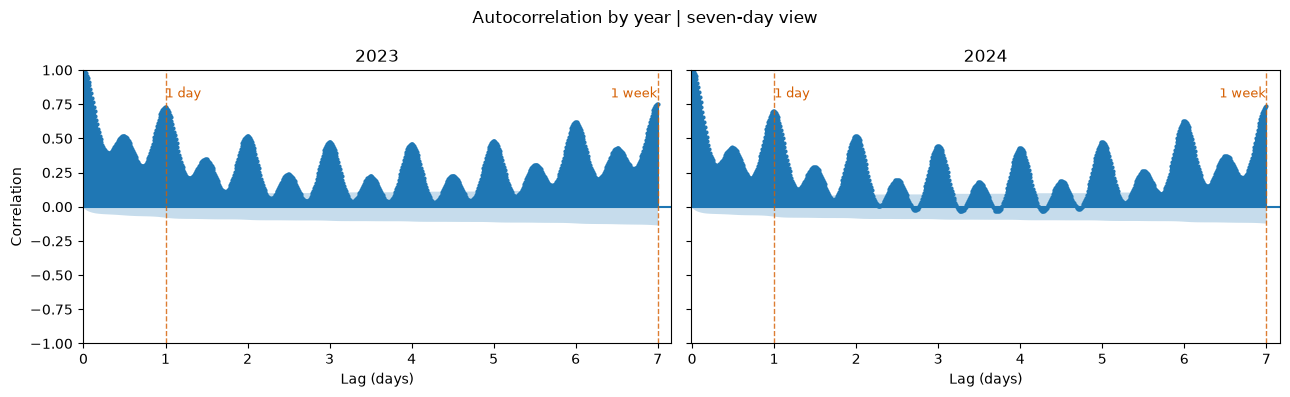

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, year in zip(axes, YEARS):
    subset = series.loc[series.index.tz_convert('Europe/Berlin').year == year]
    plot_acf(subset, lags=672, fft=True, ax=ax, zero=False, markersize=2)
    for lag, label, height in [(96, '1 day', .94), (672, '1 week', .94)]:
        ax.axvline(lag, color=COLORS[1], linestyle='--', linewidth=1, alpha=.8)
        ax.text(lag, height, label, transform=ax.get_xaxis_transform(), ha='right' if lag == 672 else 'left', va='top', fontsize=9, color=COLORS[1])
    ax.set(title=str(year), xlabel='Lag (days)', xlim=(-1, 688))
    ax.set_xticks([0, 96, 192, 288, 384, 480, 576, 672], [0, 1, 2, 3, 4, 5, 6, 7])
axes[0].set_ylabel('Correlation')
fig.suptitle('Autocorrelation by year | seven-day view')
fig.tight_layout()
fig.savefig('autocorrelation_yearly_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

### Observations

The recent-lag ACF falls from about 0.997 at 15 minutes to 0.957 at one hour. It declines through the first several hours. The daily view shows a smaller rise around half a day and a return to about 0.71 at one day. This shape reflects strong short-term persistence combined with repeated features within the daily cycle.

The seven-day view shows recurring daily peaks and a larger peak near one week, around 0.74. The weekly relationship exceeds the two-day and three-day relationships, which agrees with the weekday–weekend structure in the overview.

The yearly hourly and daily comparisons have similar shapes, with slightly weaker ordinary correlations in 2024. One-hour correlation is about 0.960 in 2023 and 0.955 in 2024, while one-day correlation falls from about 0.731 to 0.698. Both years share the daily and weekly peaks. Between the daily peaks, the 2024 ACF falls closer to zero and occasionally below it, while the 2023 curve stays more positive. This is consistent with stronger contrasts within the daily cycle in 2024. Recent and seasonal lags are therefore reasonable candidates whose predictive value requires validation.

## 7. Partial autocorrelation

Partial correlations describe the remaining relationship at each lag after accounting for all intervening lags. One observation lag represents 15 minutes, so lags 4, 96, and 672 correspond to one hour, one day, and one week.

### 7.1 Recent dependence: 15 minutes to six hours

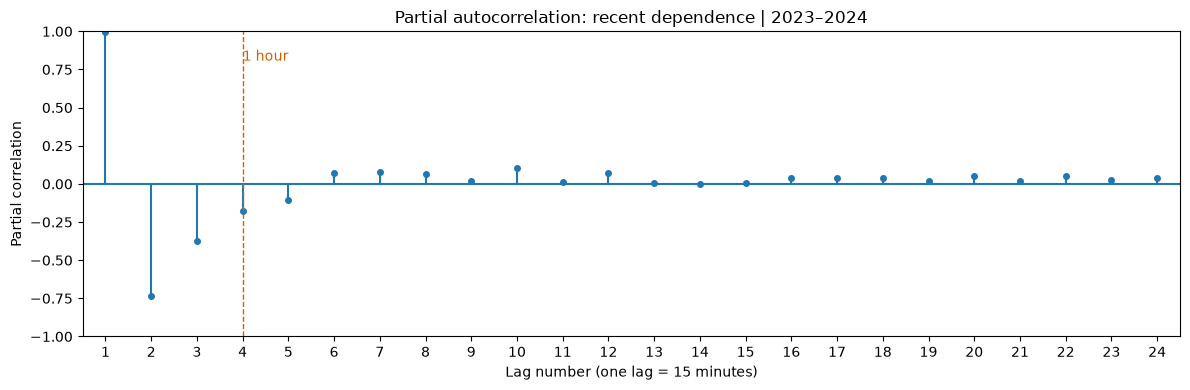

In [22]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(series, lags=24, method='ldbiased', ax=ax, zero=False, markersize=4)
ax.axvline(4, color=COLORS[1], linestyle='--', linewidth=1)
ax.text(4, .94, '1 hour', transform=ax.get_xaxis_transform(), ha='left', va='top', color=COLORS[1])
ax.set(title='Partial autocorrelation: recent dependence | 2023–2024', xlabel='Lag number (one lag = 15 minutes)', ylabel='Partial correlation', xlim=(.5, 24.5))
ax.set_xticks(range(1, 25))
fig.tight_layout()
fig.savefig('partial_autocorrelation_recent_lags.png', dpi=160, bbox_inches='tight')
plt.show()

### 7.2 Daily dependence: 24 hours

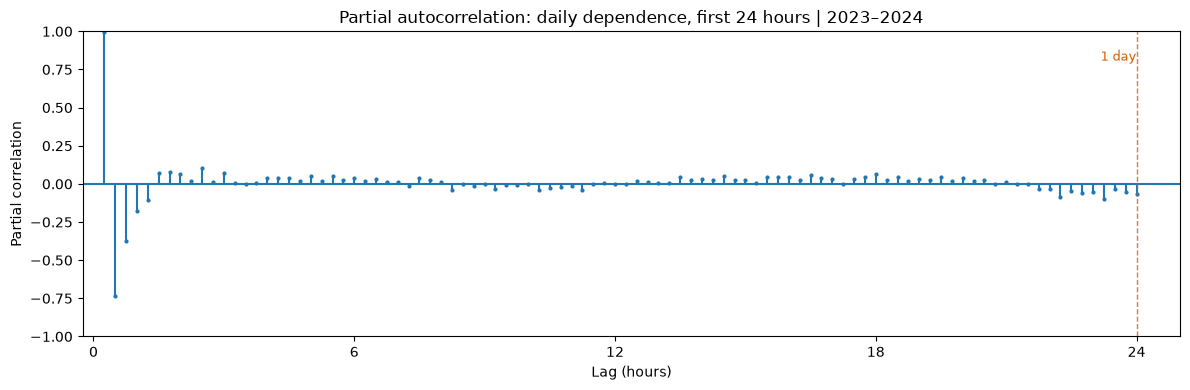

In [23]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(series, lags=96, method='ldbiased', ax=ax, zero=False, markersize=2)
for lag, label, height in [(96, '1 day', .94)]:
    ax.axvline(lag, color=COLORS[1], linestyle='--', linewidth=1, alpha=.8)
    ax.text(lag, height, label, transform=ax.get_xaxis_transform(), ha='right' if lag == 96 else 'left', va='top', fontsize=9, color=COLORS[1])
ax.set(title='Partial autocorrelation: daily dependence, first 24 hours | 2023–2024', xlabel='Lag (hours)', ylabel='Partial correlation', xlim=(-1, 100))
ax.set_xticks([0, 24, 48, 72, 96], [0, 6, 12, 18, 24])
fig.tight_layout()
fig.savefig('partial_autocorrelation_daily_lags.png', dpi=160, bbox_inches='tight')
plt.show()

### 7.3 Weekly dependence: seven days

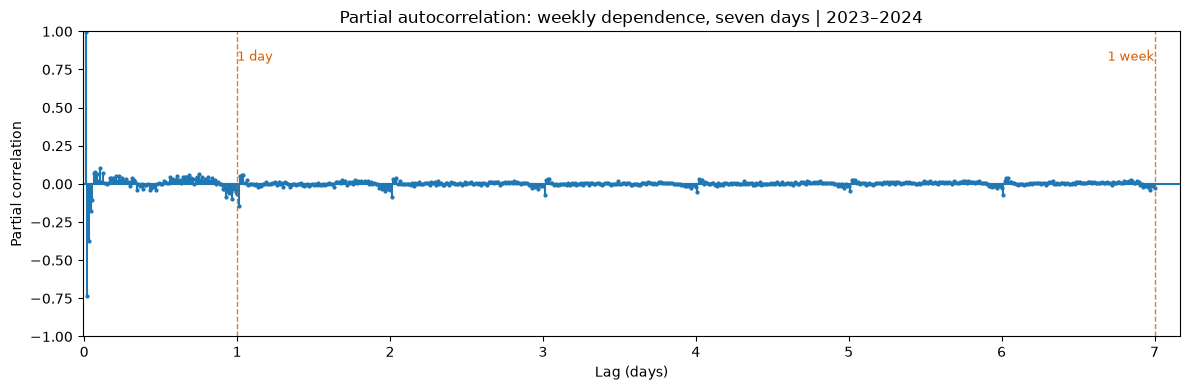

In [24]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(series, lags=672, method='ldbiased', ax=ax, zero=False, markersize=2)
for lag, label, height in [(96, '1 day', .94), (672, '1 week', .94)]:
    ax.axvline(lag, color=COLORS[1], linestyle='--', linewidth=1, alpha=.8)
    ax.text(lag, height, label, transform=ax.get_xaxis_transform(), ha='right' if lag == 672 else 'left', va='top', fontsize=9, color=COLORS[1])
ax.set(title='Partial autocorrelation: weekly dependence, seven days | 2023–2024', xlabel='Lag (days)', ylabel='Partial correlation', xlim=(-1, 688))
ax.set_xticks([0, 96, 192, 288, 384, 480, 576, 672], [0, 1, 2, 3, 4, 5, 6, 7])
fig.tight_layout()
fig.savefig('partial_autocorrelation_seasonal_lags.png', dpi=160, bbox_inches='tight')
plt.show()

### 7.4 Yearly comparison: recent hourly dependence

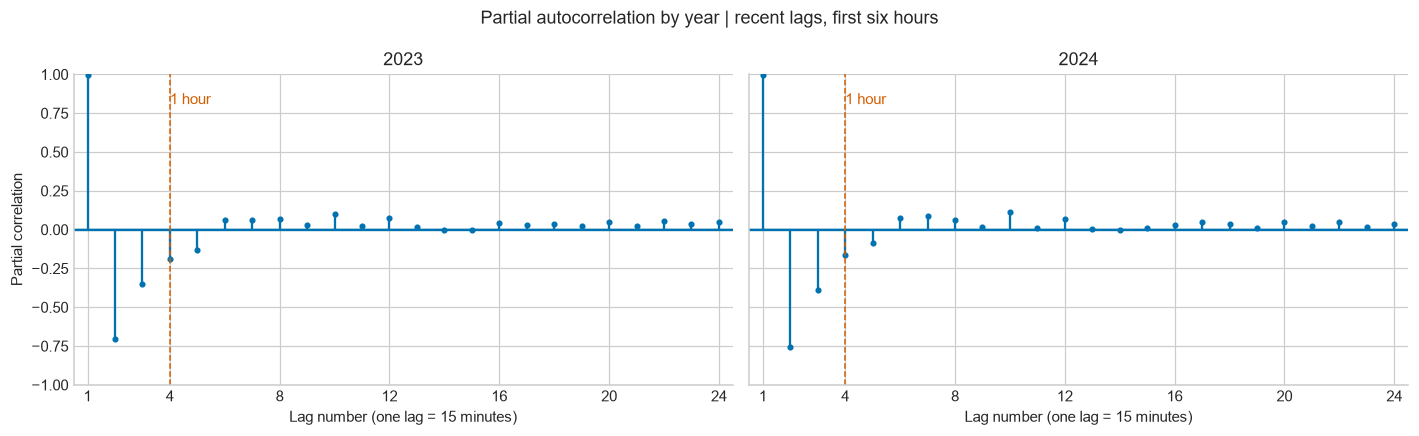

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, year in zip(axes, YEARS):
    subset = series.loc[series.index.tz_convert('Europe/Berlin').year == year]
    plot_pacf(subset, lags=24, method='ldbiased', ax=ax, zero=False, markersize=3)
    ax.axvline(4, color=COLORS[1], linestyle='--', linewidth=1)
    ax.text(4, .94, '1 hour', transform=ax.get_xaxis_transform(), ha='left', va='top', color=COLORS[1])
    ax.set(title=str(year), xlabel='Lag number (one lag = 15 minutes)', xlim=(.5, 24.5))
    ax.set_xticks([1, 4, 8, 12, 16, 20, 24])
axes[0].set_ylabel('Partial correlation')
fig.suptitle('Partial autocorrelation by year | recent lags, first six hours')
fig.tight_layout()
fig.savefig('partial_autocorrelation_yearly_recent_lags.png', dpi=160, bbox_inches='tight')
plt.show()

### 7.5 Yearly comparison: 24 hours

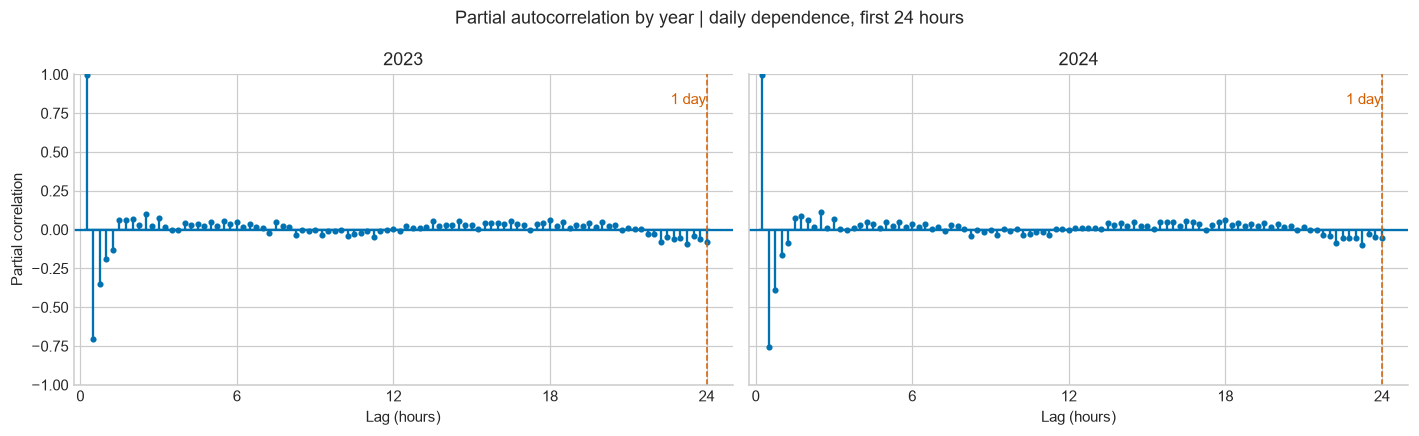

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, year in zip(axes, YEARS):
    subset = series.loc[series.index.tz_convert('Europe/Berlin').year == year]
    plot_pacf(subset, lags=96, method='ldbiased', ax=ax, zero=False, markersize=3)
    ax.axvline(96, color=COLORS[1], linestyle='--', linewidth=1)
    ax.text(96, .94, '1 day', transform=ax.get_xaxis_transform(), ha='right', va='top', color=COLORS[1])
    ax.set(title=str(year), xlabel='Lag (hours)', xlim=(-1, 100))
    ax.set_xticks([0, 24, 48, 72, 96], [0, 6, 12, 18, 24])
axes[0].set_ylabel('Partial correlation')
fig.suptitle('Partial autocorrelation by year | daily dependence, first 24 hours')
fig.tight_layout()
fig.savefig('partial_autocorrelation_yearly_daily_lags.png', dpi=160, bbox_inches='tight')
plt.show()

### 7.6 Yearly comparison: seven days

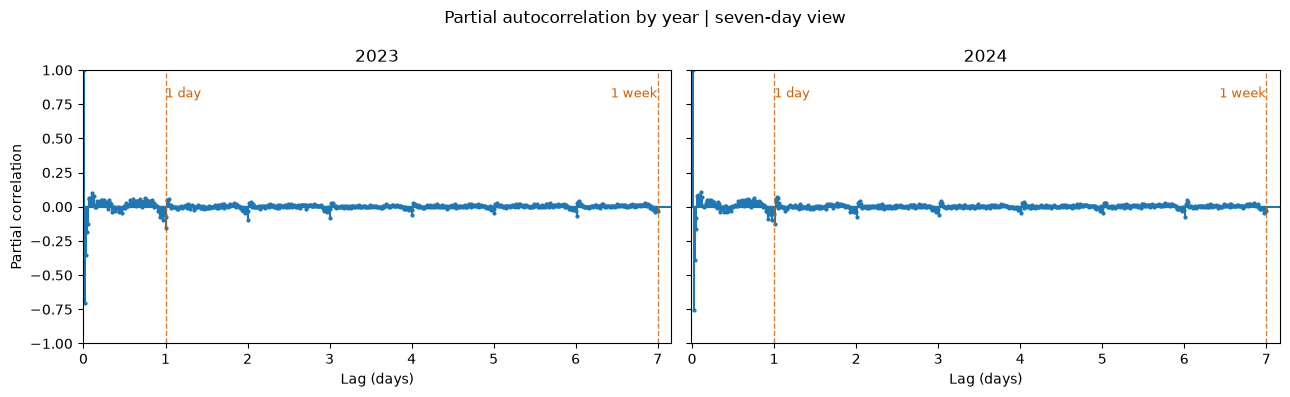

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, year in zip(axes, YEARS):
    subset = series.loc[series.index.tz_convert('Europe/Berlin').year == year]
    plot_pacf(subset, lags=672, method='ldbiased', ax=ax, zero=False, markersize=2)
    for lag, label, height in [(96, '1 day', .94), (672, '1 week', .94)]:
        ax.axvline(lag, color=COLORS[1], linestyle='--', linewidth=1, alpha=.8)
        ax.text(lag, height, label, transform=ax.get_xaxis_transform(), ha='right' if lag == 672 else 'left', va='top', fontsize=9, color=COLORS[1])
    ax.set(title=str(year), xlabel='Lag (days)', xlim=(-1, 688))
    ax.set_xticks([0, 96, 192, 288, 384, 480, 576, 672], [0, 1, 2, 3, 4, 5, 6, 7])
axes[0].set_ylabel('Partial correlation')
fig.suptitle('Partial autocorrelation by year | seven-day view')
fig.tight_layout()
fig.savefig('partial_autocorrelation_yearly_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

### Observations

The 15-minute partial autocorrelation is about 0.997, followed by large negative values at lags 2–5. At one hour, the PACF is about −0.177 after accounting for the preceding 15-, 30-, and 45-minute observations. This conditional relationship can coexist with the strongly positive ordinary one-hour correlation.

The PACF is about −0.066 at one day and −0.029 at one week. At the weekly lag, all 671 intervening lags are accounted for. The much smaller remaining relationship suggests that much of the ordinary weekly association is represented through more recent observations. Its usefulness in a forecasting model still depends on which other inputs and lags the model actually uses.

The yearly hourly comparisons show the same dominant first lag and negative conditional effects over the following intervals. The one-hour PACF is about −0.188 in 2023 and −0.166 in 2024. The daily comparisons show smaller negative values at one day, about −0.078 and −0.055, respectively, and both years retain small negative weekly values. Smaller oscillations continue through the seasonal view, with no clean cutoff for choosing one autoregressive order. The recent view separates the first few large conditional effects, while the daily and weekly views reveal smaller effects over longer time scales.

## 8. Differenced views

### 8.1 First-difference ACF

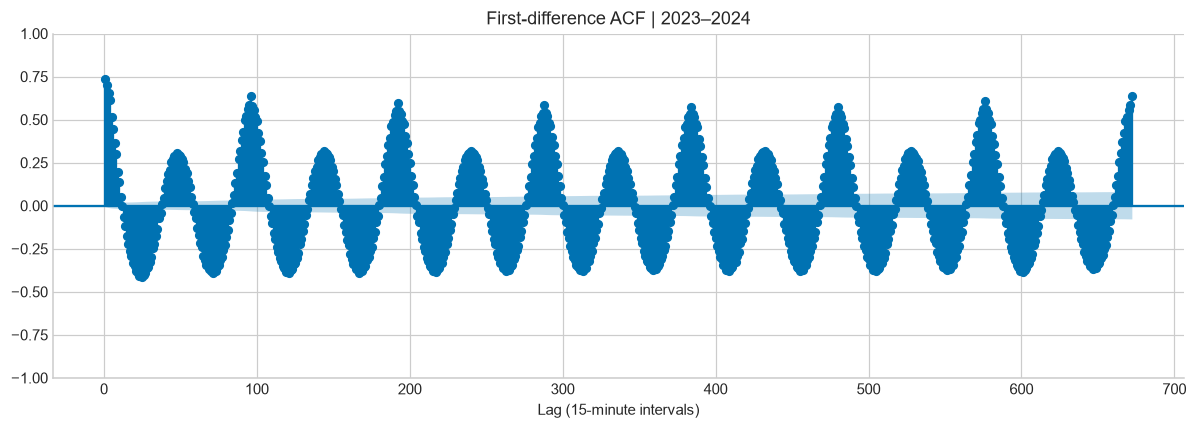

In [33]:
fig, ax = plt.subplots()
plot_acf(series.diff(1).dropna(), lags=672, fft=True, ax=ax, zero=False)
ax.set(title='First-difference ACF | 2023–2024', xlabel='Lag (15-minute intervals)')
fig.tight_layout()
fig.savefig('differenced_views_first_difference_acf.png', dpi=160, bbox_inches='tight')
plt.show()

### 8.2 Daily-difference ACF

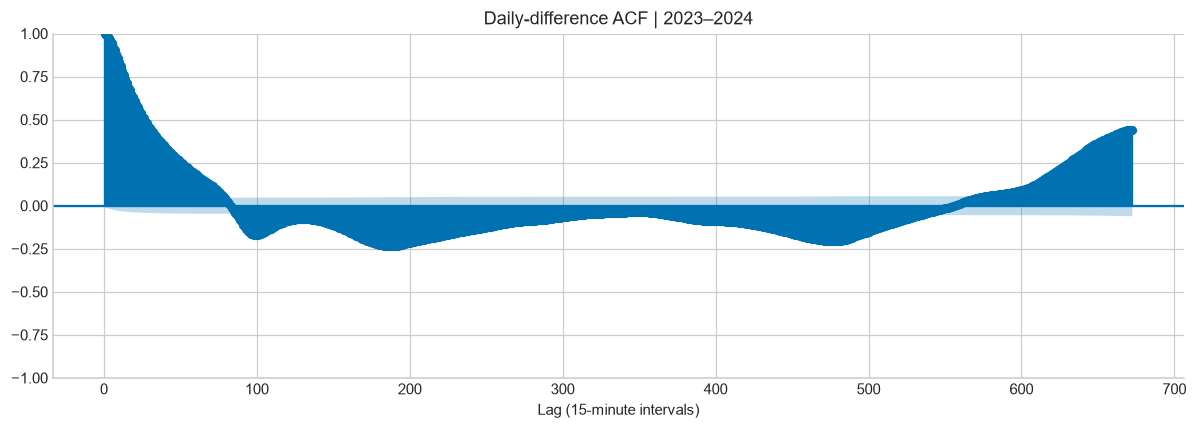

In [34]:
fig, ax = plt.subplots()
plot_acf(series.diff(96).dropna(), lags=672, fft=True, ax=ax, zero=False)
ax.set(title='Daily-difference ACF | 2023–2024', xlabel='Lag (15-minute intervals)')
fig.tight_layout()
fig.savefig('differenced_views_daily_difference_acf.png', dpi=160, bbox_inches='tight')
plt.show()

### 8.3 First-difference PACF

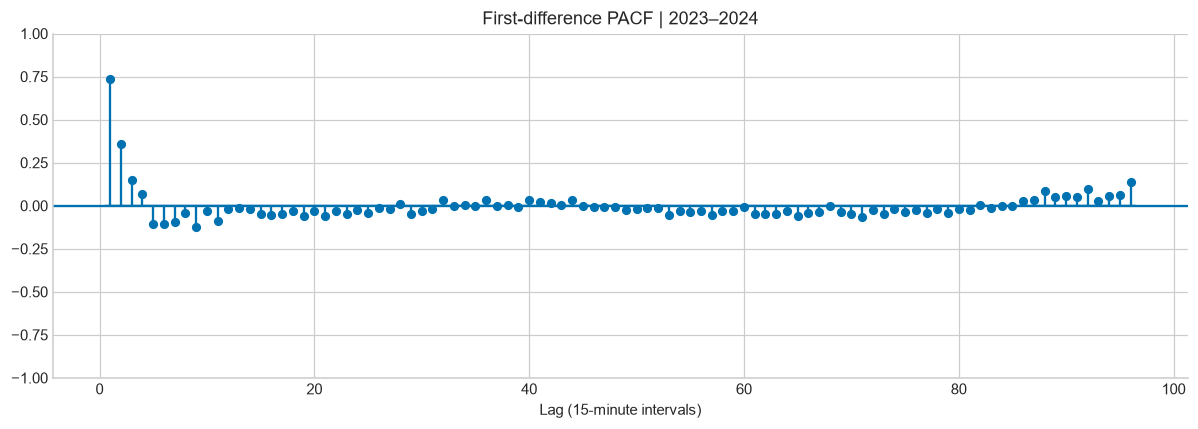

In [35]:
fig, ax = plt.subplots()
plot_pacf(series.diff(1).dropna(), lags=96, method='ywm', ax=ax, zero=False)
ax.set(title='First-difference PACF | 2023–2024', xlabel='Lag (15-minute intervals)')
fig.tight_layout()
fig.savefig('differenced_views_first_difference_pacf.png', dpi=160, bbox_inches='tight')
plt.show()

### Observations

First differencing reduces the near-unit persistence, but the changes still follow a clear daily rhythm. Their ACF is about 0.63 at one day and 0.64 at one week, with negative stretches between the recurring peaks. The first-difference PACF is strongest at the first few intervals and rises again near the daily lag.

Daily differencing weakens the daily peak and leaves a broad weekly pattern. Its ACF is negative around one day and returns to about 0.44 at one week. Both transformed series retain temporal structure, so differencing alone does not remove the dependence that a forecasting model needs to capture.

## 9. Interpretation

Daily and weekly correlations indicate persistence at forecasting-relevant time scales. These associations can motivate candidate lags, whose predictive value requires chronological validation.

In [5]:
display(Markdown(f'Observed residual-load correlations are **{series.autocorr(4):.3f} at one hour**, **{series.autocorr(96):.3f} at one day** and **{series.autocorr(672):.3f} at one week**. Daily and weekly lags are candidates for validation. ACF/PACF bands are approximate pointwise reference intervals. Inspecting many lags limits significance-based feature selection. Differencing is diagnostic and leaves model configurations unchanged.'))

Observed residual-load correlations are **0.957 at one hour**, **0.714 at one day** and **0.747 at one week**. Daily and weekly lags are candidates for validation. ACF/PACF bands are approximate pointwise reference intervals. Inspecting many lags limits significance-based feature selection. Differencing is diagnostic and leaves model configurations unchanged.

## 10. Conclusions and modelling implications

Residual load shows strong persistence at short time scales, with correlations of 0.997 at 15 minutes and 0.957 at one hour. The recent-lag PACF is dominated by the first observation and several following conditional effects, indicating substantial overlap among neighbouring values. Recent history is therefore a sensible source of forecasting information. Its contribution to a full 24-hour forecast still requires validation, even when forecasts are updated hourly.

Yearly comparisons show similar recent-lag, daily, and weekly structures, with slightly weaker ordinary hourly and daily correlations in 2024. Ordinary correlation is about 0.714 at one day and 0.747 at one week, making these time scales useful candidates for model context. Their partial correlations are much smaller, around −0.066 and −0.029, after accounting for all intervening lags. This indicates that much of the seasonal association overlaps with information in the intervening history. A model's actual lag selection and structure determine how much additional value daily or weekly information can provide.

The decomposition separates recurring daily peaks and lower weekend levels while leaving substantial irregular variation, especially during spring and summer 2024. First and daily differencing also leave clear temporal dependence. Forecasting approaches therefore need to represent recurring cycles alongside departures from those cycles. The smaller PACF effects across longer lags provide no clean cutoff for selecting one autoregressive order.

Recent, daily, and weekly history remain defensible candidates, with the existing seven-day context providing a reasonable starting point. The best context length, lag combination, and treatment of differencing require chronological validation on development data, followed by the separate held-out test. These two development years support the observed patterns and their year-to-year comparison, with limited evidence for their longer-term stability.